# Benchmark 4: Lorenz System

Lorenz system with $\gamma = 10$, $\theta = \frac{8}{3}$, and pitchfork bifurcation at $\rho = 1$:
$$\dot{u} = f(u, \rho) = \begin{pmatrix} \gamma(y - x) \\ x(\rho - z) - y \\ xy - \theta z \end{pmatrix}, \qquad u = (x, y, z)^\top$$

1. Uniqueness regime.
2. Three-solution pitchfork regime.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style, plot_3d

set_plot_style(usetex=True)

gamma = 10.0
theta = 8.0 / 3.0

def rhs(u, mu):
    x, y, z = u[0], u[1], u[2]
    return np.array([
        gamma * (y - x),
        x * (mu - z) - y,
        x * y - theta * z,
    ])

def jac(u, mu):
    x, y, z = u[0], u[1], u[2]
    J = np.empty((3, 3, len(mu)))
    J[0, 0], J[0, 1], J[0, 2] = -gamma, gamma, 0.0
    J[1, 0], J[1, 1], J[1, 2] = mu - z, -1.0, -x
    J[2, 0], J[2, 1], J[2, 2] = y, x, -theta
    return J

def exact_branches(bounds):
    rho_ex = np.linspace(bounds[0], bounds[1], 600)
    zeros = np.zeros_like(rho_ex)
    curves = [(rho_ex, np.vstack([zeros, zeros, zeros]))]

    if np.any(rho_ex >= 1.0):
        pos = np.where(rho_ex >= 1.0, rho_ex - 1.0, np.nan)
        xy = np.sqrt(theta * pos)
        curves += [
            (rho_ex, np.vstack([xy, xy, pos])),
            (rho_ex, np.vstack([-xy, -xy, pos])),
        ]
    return curves

def plot_lorenz(solver, branches):
    exact = exact_branches(solver.mu_bounds)
    views = [
        ((0, 1), (r"$x$", r"$y$")),
        ((0, 2), (r"$x$", r"$z$")),
        ((1, 2), (r"$y$", r"$z$")),
    ]
    labels = [rf"Branch {idx + 1}" for idx in range(len(branches))]
    fig = plt.figure(figsize=(15, 4.8))
    branch_labels = [rf"Branch {idx + 1}" for idx in range(len(branches))]
    for k, (pair, labels) in enumerate(views, start=1):
        ax = fig.add_subplot(1, 3, k, projection="3d")
        plot_3d(solver, branches, exact, idx_pair=pair, labels=labels,
                branch_labels=branch_labels if k == 1 else None,
                exact_label=r"Exact $\bar{u}$" if k == 1 else None,
                zlabel=r"$\rho$", ax=ax)
    plt.tight_layout()
    plt.show()

## 1. Uniqueness regime

Before the bifurcation at $\rho = 1$, on $I_\rho = [0, 1]$, a unique equilibrium exists and satisfies the global uniqueness hypotheses.

Found 1 branch(es) on (0.0, 1.0)


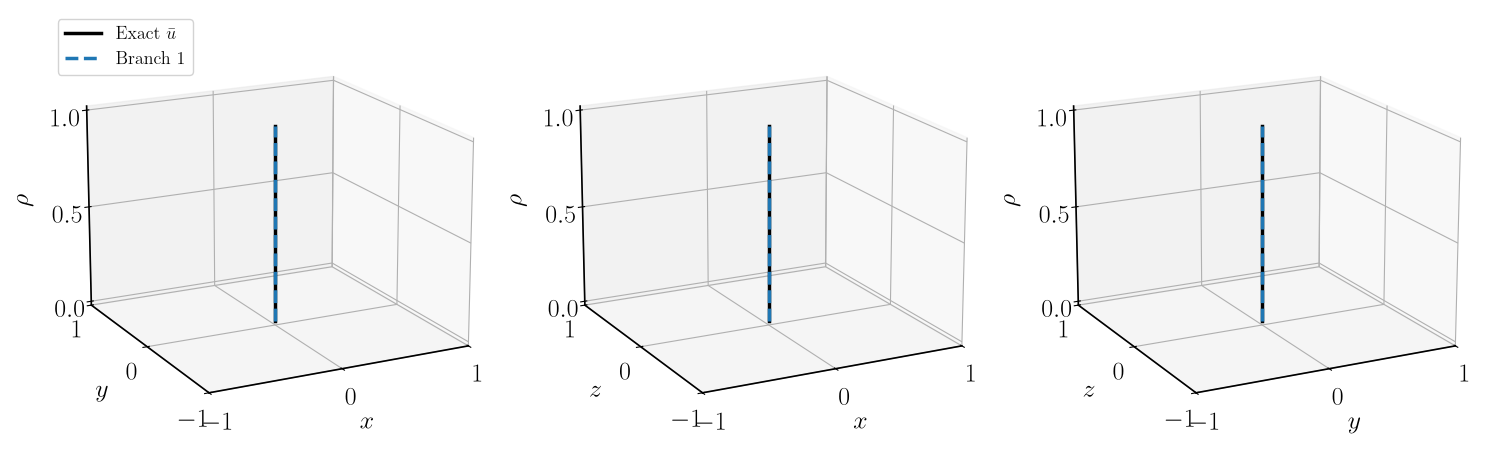

In [2]:
bounds_uq = (0.0, 1.0)
N = 20
solver_uq = PCEGalerkin(rhs, jac, mu_bounds=bounds_uq, state_dim=3, quad_order=100)
branches_uq = solver_uq.find_branches(N, n_samples=20, seed=42, unique_tol=1e-3, box=(-2.5, 2.5))
print(f"Found {len(branches_uq)} branch(es) on {bounds_uq}")
plot_lorenz(solver_uq, branches_uq)

## 2. Three-solution regime

Across $I_\rho = [1.0, 2.0]$, degree continuation reconstructs all the branches

Found 3 branch(es) on (1.0, 2.0)


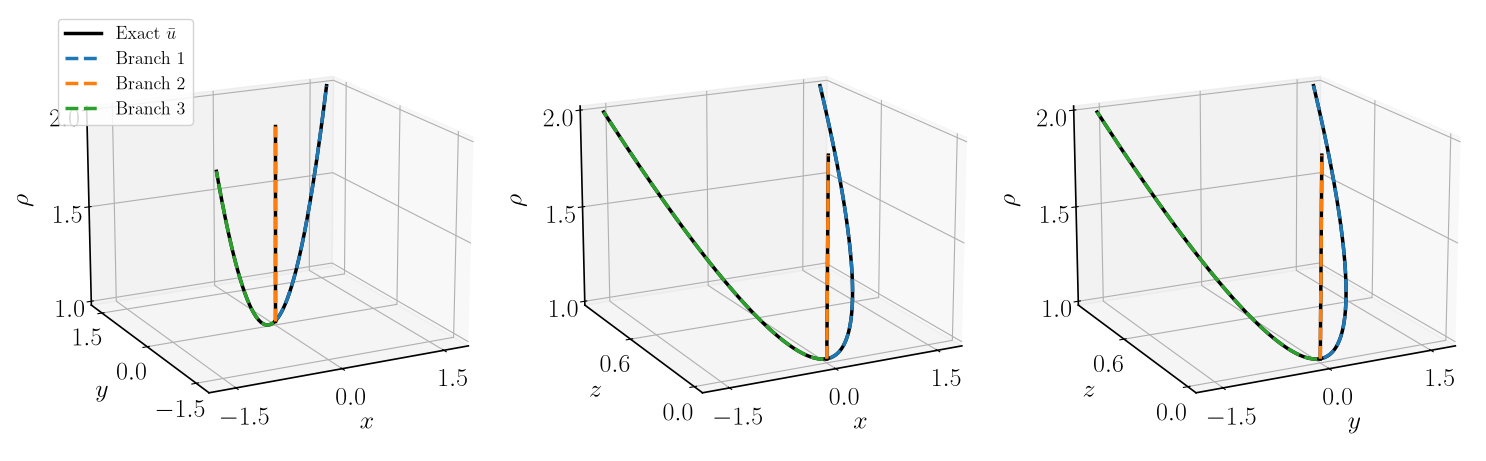

In [3]:
bounds_pf = (1.0, 2.0)
N = 20
solver_pf = PCEGalerkin(rhs, jac, mu_bounds=bounds_pf, state_dim=3, quad_order=100)
branches_pf = solver_pf.find_branches(N, n_samples=20, seed=42, unique_tol=1e-3, box=(-2.5, 2.5))
print(f"Found {len(branches_pf)} branch(es) on {bounds_pf}")
plot_lorenz(solver_pf, branches_pf)